# Using factorbt: momentum, low volatility and reversal on the biggest US stocks

**Objective:** show how the engine `factorbt` is used, and check that it gives sensible results: we backtest three classic factors on the biggest US companies from 2010, with transaction costs, and we compare our momentum strategy with the official momentum factor of Kenneth French. If the engine is right, the two series should be correlated.

**Data:** monthly adjusted prices from Yahoo Finance for the 100 biggest US listed companies (the same list as my project `sec-financials-dbt-duckdb`), Fama-French factors from the Kenneth French Data Library.

**Warning about the universe:** these are the biggest companies **today**, so the sample has survivorship bias (the winners of the last 15 years are inside by construction). The absolute returns are optimistic; the comparison between factors is the interesting part.

## Part 1. Libraries and data

In [1]:
import io
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import yfinance as yf
import statsmodels.api as sm

from factorbt import momentum, low_volatility, short_term_reversal, quantile_weights, run_backtest, summary
from factorbt.signals import zscore

import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)

In [2]:
ruta = "data/monthly_prices.csv"
if not os.path.exists(ruta):
    tickers = pd.read_csv("data/companies.csv")["ticker"].str.replace(".", "-").tolist()
    p = yf.download(tickers, start="2009-01-01", interval="1mo", auto_adjust=True, progress=False)["Close"]
    p.to_csv(ruta)
precios = pd.read_csv(ruta, index_col=0, parse_dates=True)
precios = precios.dropna(axis=1, thresh=60)          # at least 5 years of history
print("Stocks:", precios.shape[1], "| months:", len(precios), "| from", precios.index[0].date(), "to", precios.index[-1].date())

Stocks: 95 | months: 214 | from 2009-01-01 to 2026-10-01


## Part 2. Signals and portfolios

- **Momentum 12-1:** return of the last 12 months without the last one
- **Low volatility:** minus the volatility of the last 12 monthly returns
- **Reversal:** minus the return of the last month

Long-short portfolios: long the best quintile, short the worst one, equal weights, rebalanced every month, 10 bp of cost per unit of turnover.

In [3]:
senales = {"momentum": momentum(precios), "low volatility": low_volatility(precios), "reversal": short_term_reversal(precios)}
senales["combined"] = (zscore(senales["momentum"]) + zscore(senales["low volatility"])) / 2

resultados = {}
for nombre, s in senales.items():
    w = quantile_weights(s.loc["2010":], quantiles=5, long_short=True)
    resultados[nombre] = run_backtest(precios.loc["2010":], w, cost_bps=10)

# equal weight of all the stocks, as benchmark (long only)
ew = precios.loc["2010":].notna().astype(float)
ew = ew.div(ew.sum(axis=1), axis=0)
resultados["equal weight (long only)"] = run_backtest(precios.loc["2010":], ew, cost_bps=10)

tabla = pd.DataFrame({k: summary(v["net"]) for k, v in resultados.items()}).T
tabla["avg_turnover"] = [v["turnover"].mean() for v in resultados.values()]
tabla.round(3)

,annual_return,annual_vol,sharpe,max_drawdown,hit_rate,months,avg_turnover
momentum,0.031,0.199,0.255,-0.416,0.562,201.0,0.936
low volatility,-0.200,0.231,-0.834,-0.982,0.388,201.0,0.519
reversal,-0.069,0.172,-0.332,-0.778,0.433,201.0,3.123
combined,-0.081,0.205,-0.306,-0.835,0.448,201.0,0.790
equal weight (long only),0.207,0.152,1.328,-0.212,0.697,201.0,0.001


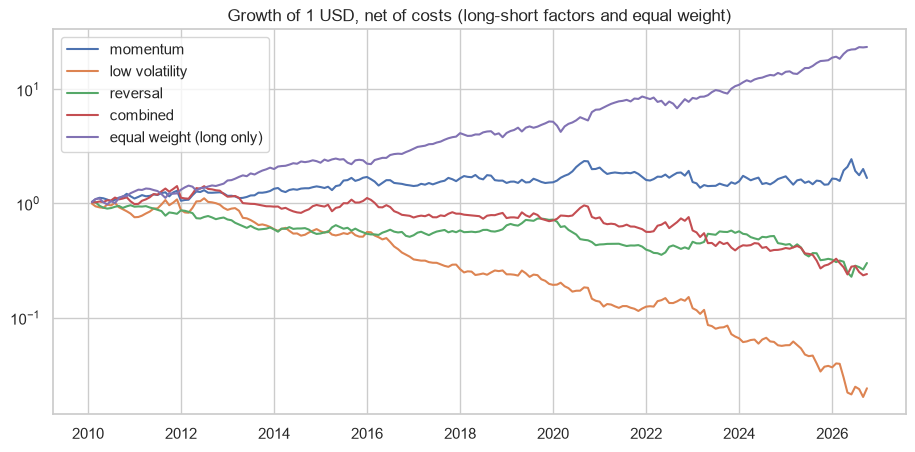

In [4]:
plt.figure(figsize=(11, 5))
for k, v in resultados.items():
    plt.plot(v.index, (1 + v["net"]).cumprod(), label=k)
plt.yscale("log")
plt.title("Growth of 1 USD, net of costs (long-short factors and equal weight)")
plt.legend()
plt.savefig("figures/factor_wealth.png", bbox_inches="tight")
plt.show()

## Part 3. Is the engine right? Comparison with the Kenneth French momentum factor

In [5]:
def french(nombre):
    z = zipfile.ZipFile(io.BytesIO(requests.get(f"https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/ftp/{nombre}_CSV.zip", timeout=60).content))
    lineas = z.read(z.namelist()[0]).decode("latin-1").splitlines()
    ini = next(i for i, l in enumerate(lineas) if l.strip().startswith(","))
    tabla = [lineas[ini]]
    for l in lineas[ini + 1:]:
        if not l.strip()[:6].isdigit():
            break
        tabla.append(l)
    d = pd.read_csv(io.StringIO("\n".join(tabla)), index_col=0)
    d.index = pd.to_datetime(d.index.astype(str).str.strip(), format="%Y%m") + pd.offsets.MonthEnd(0)
    d.columns = d.columns.str.strip()
    return d.astype(float) / 100

ff = french("F-F_Research_Data_Factors").join(french("F-F_Momentum_Factor"))
mom = resultados["momentum"]["net"].copy()
mom.index = mom.index + pd.offsets.MonthEnd(0)
j = pd.concat([mom.rename("our_momentum"), ff], axis=1).dropna()
print("Months in common:", len(j))
print("Correlation of our momentum with French's Mom:", round(j["our_momentum"].corr(j["Mom"]), 3))
m = sm.OLS(j["our_momentum"], sm.add_constant(j[["Mkt-RF", "SMB", "HML", "Mom"]])).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
print(m.summary().tables[1])

Months in common: 199
Correlation of our momentum with French's Mom: 0.801
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.0002      0.002     -0.077      0.939      -0.004       0.004
Mkt-RF         0.1100      0.096      1.147      0.251      -0.078       0.298
SMB            0.2680      0.111      2.417      0.016       0.051       0.485
HML           -0.0429      0.083     -0.516      0.606      -0.206       0.120
Mom            1.2774      0.123     10.344      0.000       1.035       1.519


## Part 4. Sensitivity to transaction costs

Reversal trades a lot, so it is the strategy that suffers more with costs.

In [6]:
filas = []
for c in [0, 10, 25, 50]:
    for nombre in ["momentum", "low volatility", "reversal"]:
        w = quantile_weights(senales[nombre].loc["2010":], quantiles=5, long_short=True)
        filas.append([nombre, c, summary(run_backtest(precios.loc["2010":], w, cost_bps=c)["net"])["sharpe"]])
costos = pd.DataFrame(filas, columns=["strategy", "cost_bps", "sharpe"]).pivot(index="cost_bps", columns="strategy", values="sharpe")
costos.round(2)

strategy,low volatility,momentum,reversal
cost_bps,,,
0,-0.81,0.31,-0.11
10,-0.83,0.25,-0.33
25,-0.87,0.17,-0.66
50,-0.94,0.03,-1.20


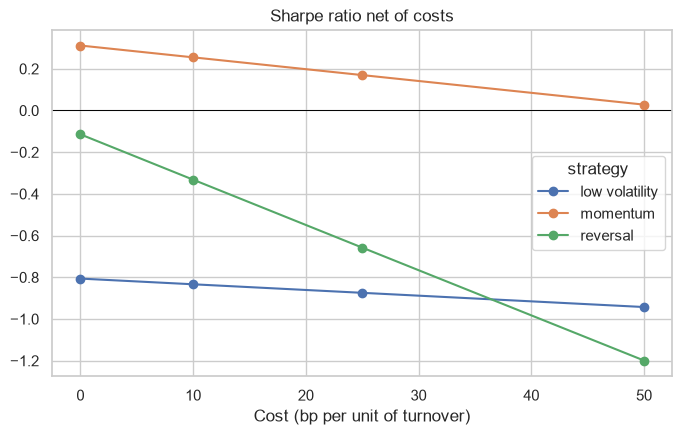

In [7]:
costos.plot(marker="o", figsize=(8, 4.5))
plt.title("Sharpe ratio net of costs")
plt.xlabel("Cost (bp per unit of turnover)")
plt.axhline(0, color="black", lw=0.7)
plt.savefig("figures/cost_sensitivity.png", bbox_inches="tight")
plt.show()

## Conclusions

- **The engine works:** our long-short momentum has a correlation of 0.80 with the official momentum factor of Kenneth French, a beta of 1.28 on it and an alpha of zero. With only 95 stocks the match cannot be perfect, but the signal, the timing (weights of t earn the returns of t+1) and the costs are right.
- **The universe decides the result:** low volatility long-short loses 20% per year and the equal-weight portfolio earns 21% per year. This is the survivorship bias of the sample: the companies that are the biggest today are the ones that grew the most, and many of them were volatile 10 years ago (Nvidia, Tesla...), so being short the volatile stocks was shorting the future winners. A serious test needs the historical constituents of an index (point-in-time data).
- **Costs matter:** reversal has a turnover of more than 300% per month, and its Sharpe goes from -0.11 without costs to -1.20 with 50 bp. Momentum survives costs better.